# 4.2.4 Cell-cell communication summary

Inés Sentís

Date of execution

In [1]:
Sys.Date()

[1] "2026-02-23"

In [2]:
suppressMessages(suppressWarnings({
library(Seurat)
library(ggplot2)
library(igraph)
library(ggraph)
library(tidyverse)
library(ComplexHeatmap)
library(circlize)
library(viridis)
library(readr)
library(dplyr)
library(glue)
library(here)
}))

## Load Data

In [3]:
get_cc_res <- function(path) {
  df_list <- Sys.glob(file.path(path, "4.2.3-cellchat_clust_p*.csv"))
  
  list_df <- lapply(df_list, function(file) {
      df <- read_csv(file, show_col_types = FALSE)

      splited <- str_split(file, "/")[[1]]
      filename <- rev(splited)[1]
      patient <- gsub("4.2.3-cellchat_clust_", "", filename)
      patient <- gsub(".csv", "", patient)
      df$patient <- patient
      df
  })
  return(list_df)
}

In [4]:
df_info <- read_csv(here(glue("utils/info_samples.csv")),show_col_types = FALSE)
df_info <- df_info %>% 
  dplyr::filter(modality =="st")

In [5]:
# first batch AVGUSTINOVA 01
source(here::here("AVGUSTINOVA_01/st_analysis/misc/paths.R"))
path <- here::here(glue::glue("{ann}/{plt_dir}"))
l1 <- get_cc_res(path)

# second batch AVGUSTINOVA 06
source(here::here("AVGUSTINOVA_06/st_analysis/misc/paths.R"))
path <- here::here(glue::glue("{ann}/{plt_dir}"))
l2 <- get_cc_res(path)

# third batch AVGUSTINOVA 09
source(here::here("AVGUSTINOVA_09/st_analysis/misc/paths.R"))
path <- here::here(glue::glue("{ann}/{plt_dir}"))
l3 <- get_cc_res(path)

# fourth batch AVGUSTINOVA 15
source(here::here("AVGUSTINOVA_15/st_analysis/misc/paths.R"))
path <- here::here(glue::glue("{ann}/{plt_dir}"))
l4 <- get_cc_res(path)

# fourth batch AVGUSTINOVA 28
source(here::here("AVGUSTINOVA_28/st_analysis/misc/paths.R"))
path <- here::here(glue::glue("{ann}/{plt_dir}"))
l5 <- get_cc_res(path)

In [6]:
df_all<- dplyr::bind_rows(l1,l2,l3,l4,l5)

In [7]:
df_all <- df_all %>%
    filter(!(patient %in%c("p1","p11")))

In [8]:
df_filt <- df_all %>%
    select(c('ligand','receptor','pathway_name','patient')) %>%
    unique() 

In [9]:
df_filt <- df_filt %>%
  group_by(ligand, receptor, pathway_name) %>%
  summarise(patients = n_distinct(patient), .groups = "drop") %>%
    arrange(desc(patients))

head(df_filt)

ligand,receptor,pathway_name,patients
<chr>,<chr>,<chr>,<int>
SPP1,ITGAV_ITGB1,SPP1,8
MDK,NCL,MK,7
IGFBP3,TMEM219,IGFBP,6
MDK,SDC2,MK,6
PROS1,AXL,PROS,6
SPP1,CD44,SPP1,6


In [10]:
lr_plot <- function(edges, ptw, global_max) {
    # Filter by pathway
    edges <- edges %>%
        filter(pathway_name == ptw)
    # Create a vector of unique node names
    nodes <- data.frame(
      name = unique(c(edges$ligand, edges$receptor)),
      stringsAsFactors = FALSE
    )

    # Assign logical type: TRUE for receptor, FALSE for ligand
    nodes$type <- nodes$name %in% edges$receptor  # receptors = TRUE, ligands = FALSE
    
    max_patients <- max(edges$patients, na.rm = TRUE)
    integer_breaks <- unique(round(pretty(c(0, max_patients), n = 4)))

    # Build graph
    graph <- graph_from_data_frame(d = edges, vertices = nodes, directed = FALSE)
    
    integer_breaks <- unique(round(pretty(c(0, global_max), n = 4)))

    # Plot
    ggraph(graph, layout = "bipartite") +
      geom_edge_link(aes(width = patients), color = "grey70", alpha = 0.7) +
      geom_node_label(aes(label = name, fill = type,label.padding = unit(0.5, "lines")),
                      color = "white", size = 6, fontface = "bold") +
      scale_fill_manual(values = c("FALSE" = "#1f78b4", "TRUE" = "#33a02c"),
                        labels = c("Ligand", "Receptor"),
                        name = "Node Type") +
      scale_edge_width(
            range = c(0.5, 5), 
            breaks = integer_breaks,  
            limits = c(0, global_max),
            name = "# Patients"      
        ) +
      theme_void() +
      theme(
          legend.position = "bottom",
          plot.margin = unit(c(0.5, 2, 0.5, 2), "cm")  # top, right, bottom, left
  )
}

In [11]:
global_max_patients <- max(df_filt$patients, na.rm = TRUE)

Warning message in geom_node_label(aes(label = name, fill = type, label.padding = unit(0.5, :
“Ignoring unknown aesthetics: label.padding”
Don't know how to automatically pick scale for object of type <simpleUnit/unit/unit_v2>. Defaulting to continuous.
Warning message:
“Using the `size` aesthetic in this geom was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` in the `default_aes` field and elsewhere instead.”


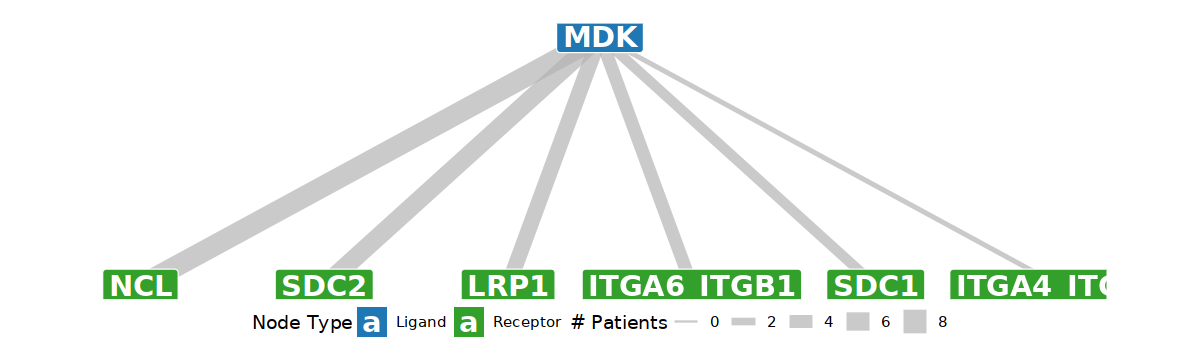

In [12]:
options(repr.plot.width = 10, repr.plot.height = 3)
lr_plot(df_filt, "MK", global_max_patients)

In [13]:
p1 <- lr_plot(df_filt, "MK",global_max_patients)

Warning message in geom_node_label(aes(label = name, fill = type, label.padding = unit(0.5, :
“Ignoring unknown aesthetics: label.padding”


Warning message in geom_node_label(aes(label = name, fill = type, label.padding = unit(0.5, :
“Ignoring unknown aesthetics: label.padding”
Don't know how to automatically pick scale for object of type <simpleUnit/unit/unit_v2>. Defaulting to continuous.


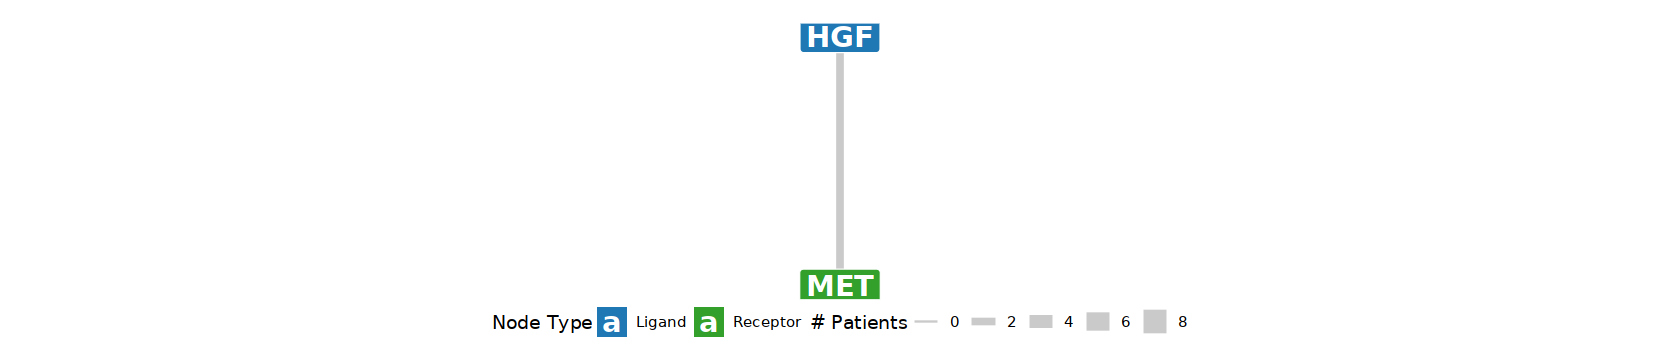

In [14]:
options(repr.plot.width = 14, repr.plot.height = 3)
lr_plot(df_filt, "HGF",global_max_patients)

In [15]:
p2 <- lr_plot(df_filt, "HGF",global_max_patients)

Warning message in geom_node_label(aes(label = name, fill = type, label.padding = unit(0.5, :
“Ignoring unknown aesthetics: label.padding”


Warning message in geom_node_label(aes(label = name, fill = type, label.padding = unit(0.5, :
“Ignoring unknown aesthetics: label.padding”
Don't know how to automatically pick scale for object of type <simpleUnit/unit/unit_v2>. Defaulting to continuous.


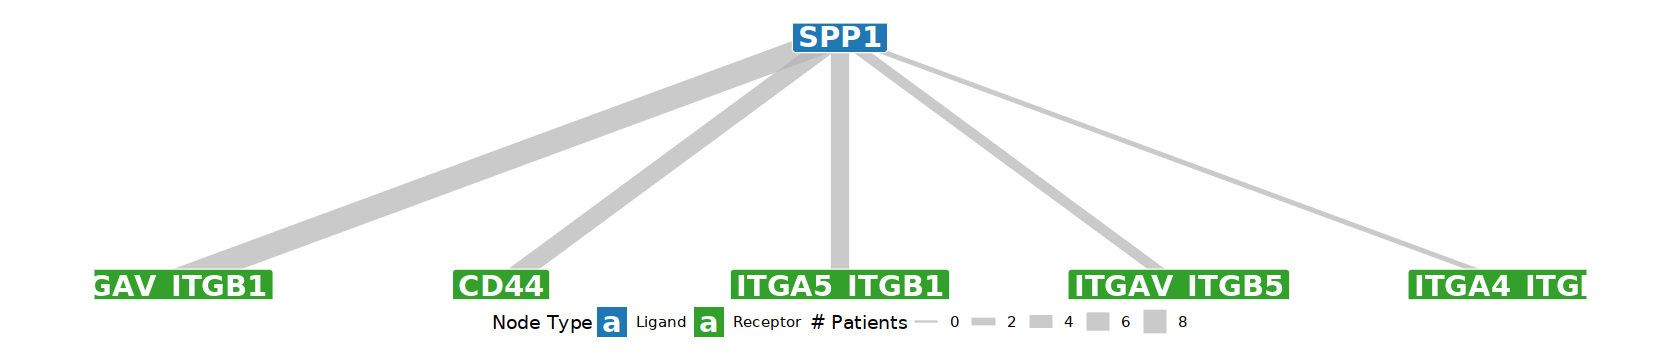

In [16]:
options(repr.plot.width = 14, repr.plot.height = 3)
lr_plot(df_filt, "SPP1",global_max_patients)

In [17]:
p3 <- lr_plot(df_filt, "SPP1",global_max_patients)

Warning message in geom_node_label(aes(label = name, fill = type, label.padding = unit(0.5, :
“Ignoring unknown aesthetics: label.padding”


Warning message in geom_node_label(aes(label = name, fill = type, label.padding = unit(0.5, :
“Ignoring unknown aesthetics: label.padding”
Don't know how to automatically pick scale for object of type <simpleUnit/unit/unit_v2>. Defaulting to continuous.


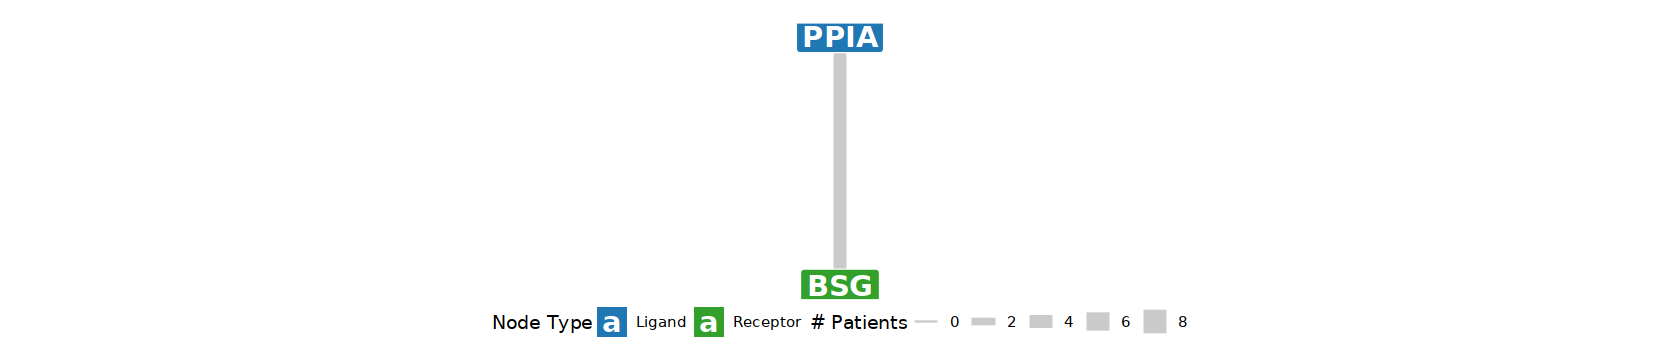

In [20]:
options(repr.plot.width = 14, repr.plot.height = 3)
lr_plot(df_filt, "CypA",global_max_patients)

In [21]:
p5 <- lr_plot(df_filt, "CypA",global_max_patients)

Warning message in geom_node_label(aes(label = name, fill = type, label.padding = unit(0.5, :
“Ignoring unknown aesthetics: label.padding”


In [22]:
source(here("AVGUSTINOVA_01_06_09_15/misc/paths.R"))
ggsave(plot = p1, width = 10, height = 3.5, dpi = 300, 
       file = here::here(glue::glue("{ann}/4.2.4-cellchat_pathway_MK.pdf")))
ggsave(plot = p2, width = 10, height = 3, dpi = 300, 
       file = here::here(glue::glue("{ann}/4.2.4-cellchat_pathway_HGF.pdf")))
ggsave(plot = p3, width = 10, height = 3, dpi = 300, 
       file = here::here(glue::glue("{ann}/4.2.4-cellchat_pathway_SPP1.pdf")))
ggsave(plot = p4, width = 10, height = 3, dpi = 300, 
       file = here::here(glue::glue("{ann}/4.2.4-cellchat_pathway_MIF.pdf")))
ggsave(plot = p5, width = 10, height = 3, dpi = 300, 
       file = here::here(glue::glue("{ann}/4.2.4-cellchat_pathway_CypA.pdf")))

Don't know how to automatically pick scale for object of type <simpleUnit/unit/unit_v2>. Defaulting to continuous.
Don't know how to automatically pick scale for object of type <simpleUnit/unit/unit_v2>. Defaulting to continuous.
Don't know how to automatically pick scale for object of type <simpleUnit/unit/unit_v2>. Defaulting to continuous.
Don't know how to automatically pick scale for object of type <simpleUnit/unit/unit_v2>. Defaulting to continuous.
Don't know how to automatically pick scale for object of type <simpleUnit/unit/unit_v2>. Defaulting to continuous.


In [30]:
# Scale again to the Max per sample,0 remains 0. The strongest value becomes 1.
df_all <- df_all %>%
  group_by(patient) %>%
  mutate(norm_prob = prob / max(prob)) %>%
  ungroup()

In [31]:
df_mean <- df_all %>%
  select(c("interaction_name_2","clusters","norm_prob","patient")) %>%
  group_by(clusters, interaction_name_2) %>%
  summarise(mean_value = mean(norm_prob, na.rm = TRUE), .groups = "drop") %>%
  arrange(interaction_name_2)

In [32]:
mat_mean <- df_mean %>%
  pivot_wider(names_from = clusters, values_from = mean_value, values_fill = NA) %>%
  column_to_rownames("interaction_name_2") %>%
  as.matrix()

In [33]:
#sample_count <- df_all %>%
#  distinct(pathway_name, patient) %>%
#  count(pathway_name, name = "n_samples") %>%
#  arrange(desc(n_samples)) %>% # Highest counts first
#  filter(n_samples > 1)

sample_count <- df_all %>%
  distinct(interaction_name_2, patient) %>%
  count(interaction_name_2, name = "n_samples") %>%
  arrange(desc(n_samples))

# Match order 
mat_mean <- mat_mean[sample_count$interaction_name_2, ]

In [34]:
# sort columns
cn <- colnames(mat_mean)

# Custom order of niches
custom_order <- c(2,0,1,3,4)

# Extract numbers from column names
nums <- do.call(rbind, regmatches(cn, gregexpr("[0-9]+", cn)))
first_num  <- as.numeric(nums[,1])
second_num <- as.numeric(nums[,2])

# Map to custom order
first_rank  <- match(first_num, custom_order)
second_rank <- match(second_num, custom_order)

# Hierarchical sort: first by first_rank, then by second_rank
mat_mean <- mat_mean[, order(first_rank, second_rank)]

In [35]:
# Tumor enrich areas as senders
#mat_mean <- mat_mean[, grepl("^N[012]", colnames(mat_mean))]

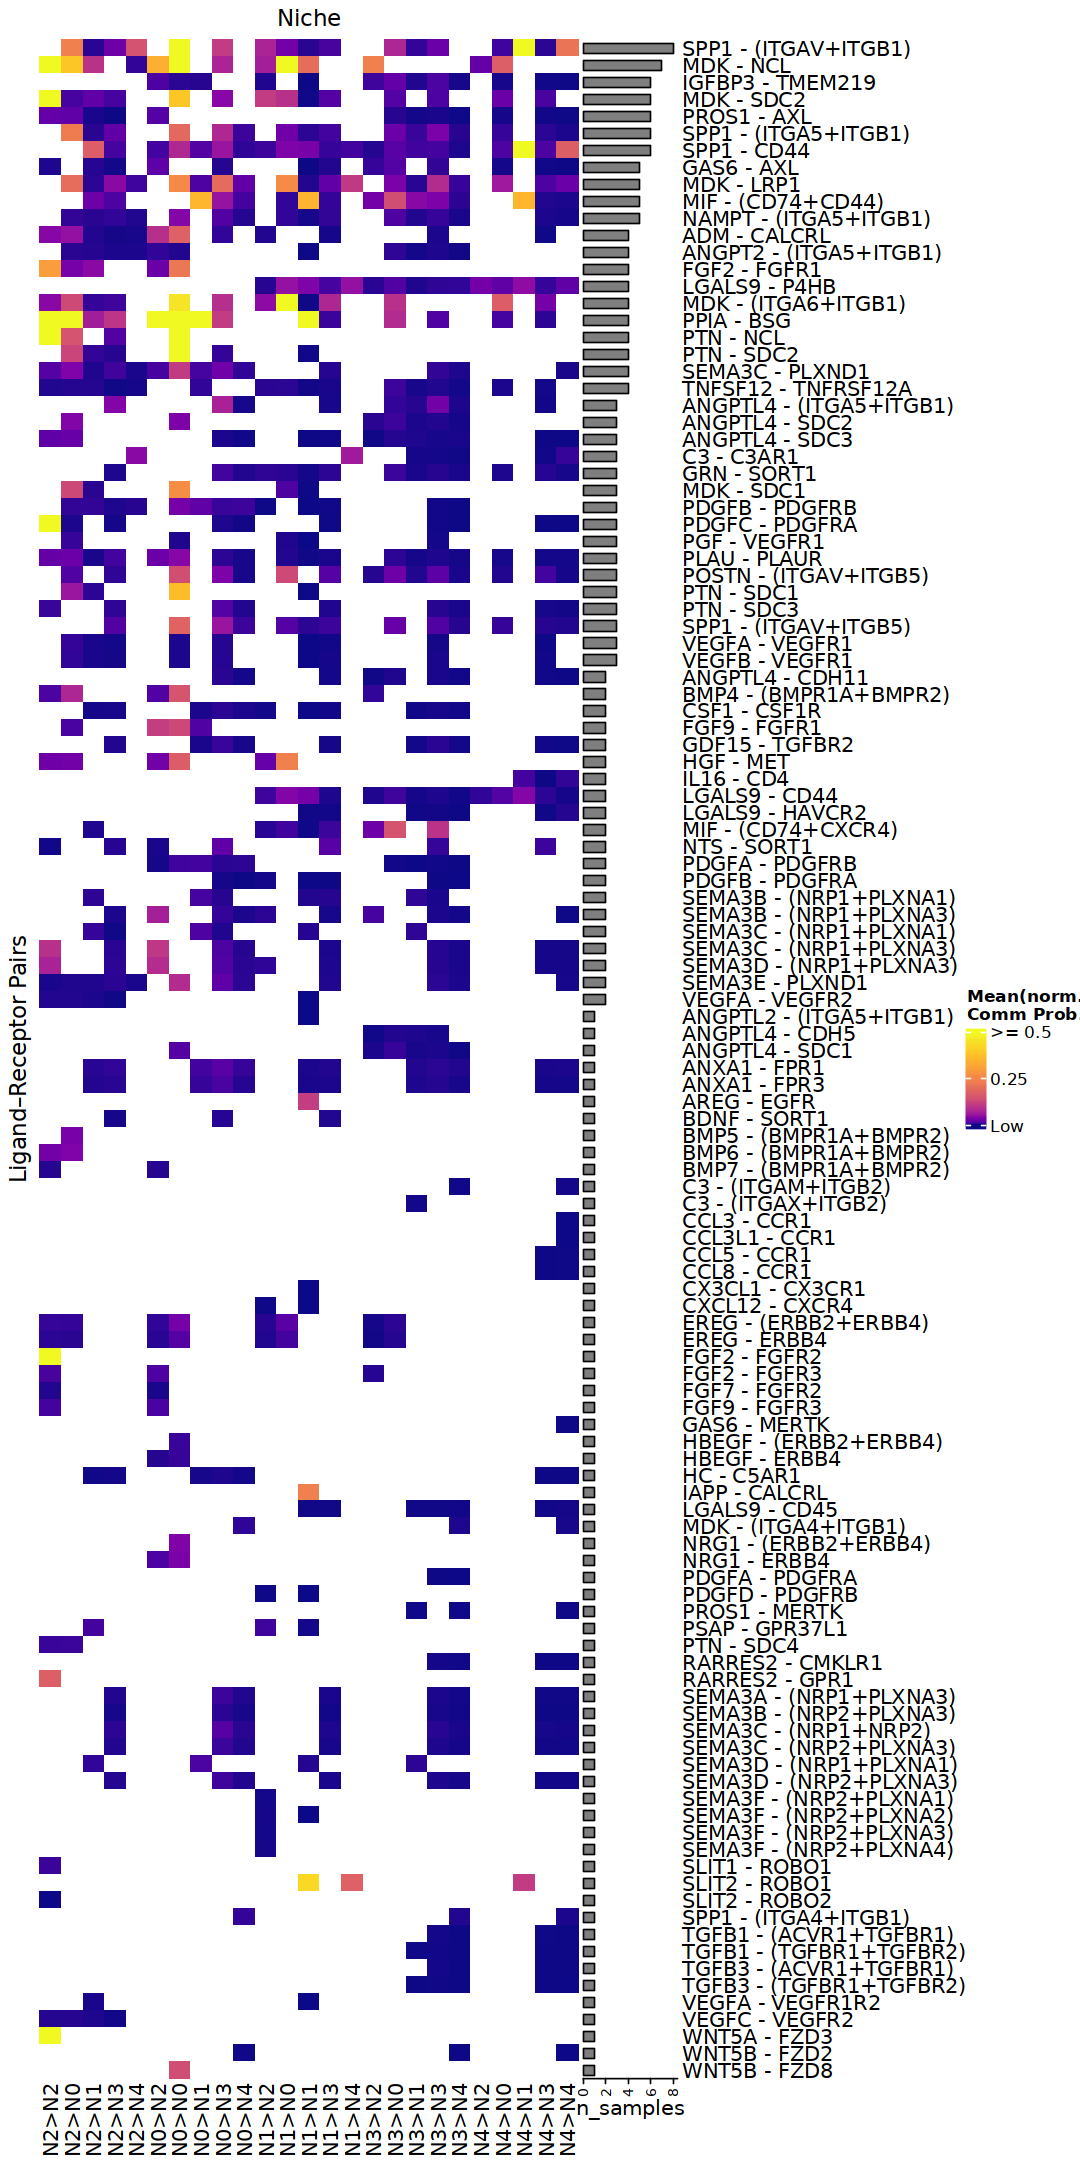

In [36]:
options(repr.plot.width = 9, repr.plot.height = 18)

bar_anno <- rowAnnotation(
  n_samples = anno_barplot(
    sample_count$n_samples,
    gp = gpar(fill = "grey50"),
    width = unit(2, "cm"),
    border = FALSE
  )
)

# Any value >= 0.5 will be displayed as the maximum color (Yellow)
visual_max <- 0.5
# Keep the Square-Root transformation to emphasize the very low end (0 to 0.1)
breaks <- seq(0, sqrt(visual_max), length.out = 100)^2

gradient_colors <- viridis(100, option = "C") 
col_fun <- colorRamp2(breaks, gradient_colors)

ht <- Heatmap(
  mat_mean,
  name = "Mean(norm.\nComm Prob.)",
  col = col_fun,
  na_col = "white",
  
  cluster_rows = FALSE,
  cluster_columns = FALSE,
  right_annotation = bar_anno,
  column_title = "Niche",
  row_title = "Ligand–Receptor Pairs",
  
  heatmap_legend_param = list(
    legend_direction = "vertical", 
    legend_width = unit(5, "cm"),
    at = c(0, 0.25, 0.5), 
    labels = c("Low", "0.25", ">= 0.5")
  ),
  
#  use_raster = TRUE,
#  raster_device = "png",
#  raster_quality = 2    
)

draw(ht)

In [37]:
pdf(here(glue("{ann}/4.2.4-CC_communication_spatial_interactions.pdf")),
   width = 9, height = 18)
draw(ht)
dev.off()

Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Ligand–Receptor Pairs' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Ligand–Receptor Pairs' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call(C_textBounds, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Ligand–Receptor Pairs' in 'mbcsToSbcs': dot substituted for <93>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Ligand–Receptor Pairs' in 'mbcsToSbcs': dot substituted for <e2>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Ligand–Receptor Pairs' in 'mbcsToSbcs': dot substituted for <80>”
Warning message in grid.Call.graphics(C_text, as.graphicsAnnot(x$label), x$x, x$y, :
“conversion failure on 'Ligand–Receptor Pairs' in

png 
  2

In [38]:
sessionInfo()

R version 4.1.1 (2021-08-10)
Platform: x86_64-conda-linux-gnu (64-bit)
Running under: CentOS Linux 7 (Core)

Matrix products: default
BLAS/LAPACK: /home/groups/singlecell/isentis/conda_envs/ines_r4.1.1/lib/libopenblasp-r0.3.24.so

locale:
 [1] LC_CTYPE=es_ES.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=es_ES.UTF-8        LC_COLLATE=es_ES.UTF-8    
 [5] LC_MONETARY=es_ES.UTF-8    LC_MESSAGES=es_ES.UTF-8   
 [7] LC_PAPER=es_ES.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=es_ES.UTF-8 LC_IDENTIFICATION=C       

attached base packages:
[1] grid      stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] here_1.0.1            glue_1.6.2            viridis_0.6.4        
 [4] viridisLite_0.4.2     circlize_0.4.15       ComplexHeatmap_2.10.0
 [7] lubridate_1.9.3       forcats_1.0.0         stringr_1.5.0        
[10] dplyr_1.1.3           purrr_1.0.2           readr_